# 02 — Exploración de WOFOST con clima histórico de Ames

Este notebook conecta los datos diarios NASA POWER ya descargados con el simulador WOFOST del repositorio y examina sus salidas por temporada. La simulación es un **prototipo de transferencia**, no una recomendación agronómica para Iowa: la implementación existente se desarrolló para Texcoco y sus parámetros de cultivo, fecha de siembra, fertilización, nitrógeno inicial y algunas reglas de manejo no están calibrados para Ames ([configuración actual](../../src/crop_models/README.md)).

Se prueba una sola secuencia de maíz continuo para aislar las métricas del modelo. Los datos históricos de clima son locales; no se solicita otra serie POWER ni se vuelven a descargar los CSV de suelo. PCSE y sus parámetros de cultivo WOFOST sí deben estar instalados/disponibles; si estos últimos no están en caché, la primera carga puede requerir acceso a internet. El [notebook 03](03_ml_smap_forecast.ipynb) hará ML sobre humedad radicular observada por SMAP; eso no equivale a corregir el rendimiento de WOFOST.

In [12]:
from pathlib import Path
import importlib.util
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'data_corn_belt').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA = ROOT / 'src' / 'data_corn_belt'
POWER_PATH = DATA / 'power_ames_2005_2025.csv'
SMAP_PATH = DATA / 'smap_ames_2015_2025.csv'
GLDAS_PATH = DATA / 'gldas_soils_ames.csv'
IGBP_PATH = DATA / 'igbp_soils_ames.csv'
PCSE_AVAILABLE = importlib.util.find_spec('pcse') is not None
print('Repositorio:', ROOT)
print('PCSE instalado:', PCSE_AVAILABLE)
for path in [POWER_PATH, SMAP_PATH, GLDAS_PATH, IGBP_PATH]:
    print(f'{path.name}: {"listo" if path.exists() else "FALTA"}')

Repositorio: /Users/allisonlara/Desktop/NASA/NASA-warm-up
PCSE instalado: True
power_ames_2005_2025.csv: listo
smap_ames_2015_2025.csv: listo
gldas_soils_ames.csv: listo
igbp_soils_ames.csv: listo


## 1. Qué simula WOFOST y qué métricas produce

WOFOST es un modelo mecanístico diario de crecimiento del cultivo; no es un modelo de regresión que aprenda rendimientos directamente. La implementación local ejecuta tres niveles: potencial (sin limitación de agua/nitrógeno), limitado por agua y limitado por agua + nitrógeno. Además guarda rendimiento seco, fechas de desarrollo/fin, estrés hídrico, absorción y contenido de N del grano, lluvia estacional, días secos y estado de agua/N al inicio de la temporada. Los detalles de las columnas están en src/crop_models/README.md.

PCSE requiere máximas y mínimas de temperatura, vapor de agua, viento, radiación, lluvia y evapotranspiración de referencia. El proveedor CSV de PCSE calcula E0/ES0/ET0 a partir de los datos meteorológicos; aquí se convierten los campos POWER locales y se deriva vapor de agua a partir de temperatura media y humedad relativa. Esa derivación y la elevación aproximada son fuentes adicionales de incertidumbre. [Guía oficial de entradas meteorológicas PCSE](https://pcse.readthedocs.io/en/stable/reference_guide.html#weather-data-in-pcse) · [WOFOST, Wageningen University & Research](https://www.wur.nl/en/research/products-services/wofost-world-food-studies).

In [13]:
power = pd.read_csv(POWER_PATH, parse_dates=['date']).set_index('date').sort_index()
smap = pd.read_csv(SMAP_PATH, parse_dates=['datetime']).set_index('datetime').sort_index()
gldas = pd.read_csv(GLDAS_PATH).iloc[0]
igbp = pd.read_csv(IGBP_PATH).iloc[0]

print('POWER:', power.shape, power.index.min().date(), '→', power.index.max().date())
print('SMAP:', smap.shape, smap.index.min(), '→', smap.index.max())
display(pd.DataFrame({'faltantes': power.isna().sum(), 'porcentaje': (100 * power.isna().mean()).round(2)}))
display(pd.DataFrame({'GLDAS porosity': [gldas['porosity']], 'IGBP field capacity (mm/100 cm)': [igbp['field_capacity']], 'IGBP wilting point (mm/100 cm)': [igbp['wilting_point']], 'IGBP total N (g/m²)': [igbp['total_nitrogen_density']]}).T.rename(columns={0: 'Ames source value'}))

POWER: (7670, 7) 2005-01-01 → 2025-12-31
SMAP: (31432, 4) 2015-03-31 01:30:00 → 2025-12-31 22:30:00


,faltantes,porcentaje
T2M,0,0.0
T2M_MAX,0,0.0
T2M_MIN,0,0.0
PRECTOTCORR,0,0.0
RH2M,0,0.0
WS2M,0,0.0
ALLSKY_SFC_SW_DWN,0,0.0


,Ames source value
GLDAS porosity,0.437000
IGBP field capacity (mm/100 cm),419.000000
IGBP wilting point (mm/100 cm),181.660995
IGBP total N (g/m²),1649.489990


## 2. Adaptar el clima local al formato de PCSE

Las unidades de origen son POWER: precipitación en mm/día, radiación en MJ/m²/día, viento en m/s, temperatura en °C y humedad relativa en %. PCSE CSV espera lluvia en mm, radiación en kJ/m²/día y vapor de agua en kPa en el archivo de entrada; su proveedor convierte a las unidades internas y calcula evapotranspiración. El vapor de agua real se aproxima como humedad relativa × presión de vapor de saturación evaluada a T2M. Se usa elevación 300 m como aproximación para Ames y los coeficientes Angström predeterminados documentados por PCSE; reemplazarlos por metadatos exactos forma parte de la calibración local.

In [14]:
LAT, LON = 42.03, -93.47
ELEVATION_M = 300.0  # aproximación; confirmar elevación de la celda POWER antes de calibrar
ANGSTROM_A, ANGSTROM_B = 0.29, 0.49

t2m = power['T2M']
saturation_vapour_kpa = 0.6108 * np.exp(17.27 * t2m / (t2m + 237.3))
vapour_kpa = saturation_vapour_kpa * power['RH2M'] / 100.0
weather_input = pd.DataFrame({
    'DAY': power.index.strftime('%Y%m%d'),
    'IRRAD': power['ALLSKY_SFC_SW_DWN'] * 1000.0,  # MJ → kJ/m²/day
    'TMIN': power['T2M_MIN'],
    'TMAX': power['T2M_MAX'],
    'VAP': vapour_kpa,
    'WIND': power['WS2M'],
    'RAIN': power['PRECTOTCORR'],  # mm/day
})
if weather_input.isna().any().any():
    raise ValueError('Hay faltantes en los campos meteorológicos requeridos; resolverlos antes de simular WOFOST.')
display(weather_input.head())
print('Filas completas:', len(weather_input), '| columnas requeridas:', list(weather_input.columns))

,DAY,IRRAD,TMIN,TMAX,VAP,WIND,RAIN
date,,,,,,,
2005-01-01,20050101,2100.0,-3.71,0.59,0.364278,5.20,1.29
2005-01-02,20050102,8200.0,-6.02,1.50,0.411767,4.14,1.51
2005-01-03,20050103,3720.0,-6.10,-2.82,0.269477,4.47,0.47
2005-01-04,20050104,2660.0,-6.48,-3.76,0.296773,4.03,2.70
2005-01-05,20050105,2320.0,-9.46,-6.42,0.273048,6.71,7.19


Filas completas: 7670 | columnas requeridas: ['DAY', 'IRRAD', 'TMIN', 'TMAX', 'VAP', 'WIND', 'RAIN']


## 3. Preparar el proveedor de clima y el suelo de Ames

El CSV meteorológico se crea en una carpeta temporal del sistema y se lee con CSVWeatherDataProvider; no se duplica el archivo de clima dentro del repositorio. Las propiedades hidráulicas se convierten desde mm de agua por 100 cm a fracciones volumétricas. GLDAS/IGBP son estimaciones de grilla, no análisis de una parcela. La provisión de nitrógeno y las reglas de fertilización heredadas son supuestos no medidos en Ames.

In [15]:
if PCSE_AVAILABLE:
    import tempfile
    import sys
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    from pcse.input import CSVWeatherDataProvider
    from src.crop_models import wofost_rotations as wofost

    weather_tmp = tempfile.TemporaryDirectory(prefix='ames_wofost_weather_')
    weather_csv = Path(weather_tmp.name) / 'ames_power_pcse.csv'
    # PCSE 6.x intenta leer SNOWDEPTH aunque no sea relevante para Ames.
    # NASA POWER no lo proporciona, así que lo representamos como NaN explícito.
    pcse_weather_input = weather_input.copy()
    pcse_weather_input['SNOWDEPTH'] = np.nan
    pcse_weather_input = pcse_weather_input[['DAY', 'IRRAD', 'TMIN', 'TMAX', 'VAP', 'WIND', 'RAIN', 'SNOWDEPTH']]
    with weather_csv.open('w', encoding='utf-8') as stream:
        stream.write('## Site characteristics\n')
        stream.write("Country = 'United States'; Station = 'Ames, Iowa'; Description = 'NASA POWER point export'; Source = 'NASA POWER'; Contact = 'not specified'\n")
        stream.write(f'Longitude = {LON}; Latitude = {LAT}; Elevation = {ELEVATION_M}; AngstromA = {ANGSTROM_A}; AngstromB = {ANGSTROM_B}; HasSunshine = False\n')
        stream.write('## Daily weather observations (missing values are NaN)\n')
        pcse_weather_input.to_csv(stream, index=False, na_rep='NaN')
    weather = CSVWeatherDataProvider(str(weather_csv), dateformat='%Y%m%d', ETmodel='PM', force_reload=True)
    if len(weather.store) != len(pcse_weather_input) or weather.first_date is None or weather.last_date is None:
        raise RuntimeError(
            f'PCSE cargó {len(weather.store)} de {len(pcse_weather_input)} días; '
            'revisa el formato y las columnas del CSV meteorológico.'
        )

    soil = dict(wofost.DummySoilDataProvider())
    soil['SMFCF'] = float(igbp['field_capacity']) / 10.0 / 100.0
    soil['SMW'] = float(igbp['wilting_point']) / 10.0 / 100.0
    soil['SM0'] = float(gldas['porosity'])
    soil['RDMSOL'] = 100
    if soil['SM0'] <= soil['SMFCF'] + soil['CRAIRC']:
        soil['SM0'] = soil['SMFCF'] + soil['CRAIRC'] + 0.01
    total_n_kg_ha = float(igbp['total_nitrogen_density']) * 10.0
    print('Proveedor PCSE:', weather)
    print('Suelo WOFOST:', {k: round(soil[k], 3) for k in ['SMFCF', 'SMW', 'SM0', 'RDMSOL']})
    print('N total IGBP convertido:', round(total_n_kg_ha), 'kg/ha')
else:
    print('PCSE no está instalado en este entorno. Instala las dependencias de requirements.txt para ejecutar las celdas de simulación.')

Proveedor PCSE: Weather data provided by: CSVWeatherDataProvider
--------Description---------
Weather data for:
Country: United States
Station: Ames, Iowa
Description: NASA POWER point export
Source: NASA POWER
Contact: not specified
----Site characteristics----
Elevation:  300.0
Latitude:  42.030
Longitude: -93.470
Data available for 2005-01-01 - 2025-12-31
Number of missing days: 0

Suelo WOFOST: {'SMFCF': 0.419, 'SMW': 0.182, 'SM0': 0.489, 'RDMSOL': 100}
N total IGBP convertido: 16495 kg/ha


## 4. Simulación histórica exploratoria: maíz continuo

La temporada del módulo existente va de marzo a febrero. Por eso se simulan las temporadas 2005–2024; la serie POWER llega hasta diciembre de 2025 y cubre el cierre de la temporada que comienza en 2024. Se descarta 2005 al resumir como año de arranque del estado de suelo. El experimento conserva la variedad, fecha fija de siembra y fertilización de la implementación existente; no representa un paquete de manejo validado para Iowa.

In [16]:
if PCSE_AVAILABLE:
    crops = wofost.YAMLCropDataProvider(wofost.Wofost81_NWLP_CWB_CNB)
    settings = {'sowing': 'fixed', 'frost_tmin_offset': 0.0, 'n_scale': 1.0}
    maize = wofost.CROPS['maize']
    display(pd.DataFrame([{
        'variedad heredada del modelo': maize['variety'],
        'siembra fija (MM-DD)': maize['earliest'],
        'fertilizante heredado (kg N/ha)': sum(amount for _, amount in maize['fertilizer']) * settings['n_scale'],
        'agua inicial supuesta (cm)': wofost.INITIAL_WATER_CM,
        'N mineral inicial supuesto (kg/ha)': wofost.INITIAL_N_KG,
        'fracción anual de N mineralizada': wofost.MINERALIZATION_RATE,
    }]))
    seasons_ames, daily_ames = wofost.simulate_rotation(
        name='continuous_maize_exploratory',
        sequence=['maize'],
        weather=weather,
        crops=crops,
        soil=soil,
        total_n=total_n_kg_ha,
        start_year=2005,
        end_year=2024,
        settings=settings,
    )
    print('Temporadas:', len(seasons_ames), '| fechas WOFOST:', daily_ames.index.min().date(), '→', daily_ames.index.max().date())
    display(seasons_ames.head())
else:
    print('Simulación omitida: se necesita PCSE.')

,variedad heredada del modelo,siembra fija (MM-DD),fertilizante heredado (kg N/ha),agua inicial supuesta (cm),N mineral inicial supuesto (kg/ha),fracción anual de N mineralizada
0,Grain_maize_202,05-15,160.0,5,10,0.005


Temporadas: 20 | fechas WOFOST: 2005-03-01 → 2025-03-01


,rotation,phase,year,crop,previous_crop,sowing,n_fertilizer_kg_ha,soil_water_at_start_mm,mineral_n_at_start_kg_ha,yield_potential_t_ha,...,frost_ended,yield_water_n_wofost_t_ha,n_uptake_kg_ha,grain_n_kg_ha,water_stress_days,rain_season_mm,rain_jul_aug_mm,longest_dry_spell_days,water_pct_of_potential,water_n_pct_of_water
0,continuous_maize_exploratory,0,2005,maize,None,2005-05-15,160.0,231.660995,10.000000,10.250744,...,False,3.849962,172.474500,58.519428,18,290.87,151.39,13,37.557883,100.000000
1,continuous_maize_exploratory,0,2006,maize,maize,2006-05-15,160.0,302.602681,4.192591,8.744999,...,False,4.675659,166.667091,71.070013,10,246.35,182.83,9,53.466660,100.000000
2,continuous_maize_exploratory,0,2007,maize,maize,2007-05-15,160.0,408.705764,3.989348,9.796245,...,False,8.937307,166.463848,112.746166,9,442.29,272.81,9,98.408143,92.707733
3,continuous_maize_exploratory,0,2008,maize,maize,2008-05-15,160.0,419.120000,4.464344,14.177995,...,False,12.606592,166.938844,121.740360,11,577.38,227.16,8,100.000000,85.865711
4,continuous_maize_exploratory,0,2009,maize,maize,2009-05-15,160.0,419.659043,3.600775,14.820542,...,False,12.824258,166.075274,124.098231,9,394.77,204.69,14,100.000000,83.733933


## 5. Métricas por temporada y niveles de limitación

Los rendimientos WOFOST están en toneladas de materia seca por hectárea. La diferencia entre potencial y limitado por agua resume el efecto hídrico en el modelo; la diferencia adicional entre agua y agua+nitrógeno resume la limitación nitrogenada bajo los parámetros elegidos. Los días con estrés y absorción de N son estados simulados, no mediciones observadas. El primer año se muestra en la tabla, pero se excluye del resumen debido al estado inicial supuesto.

,year,sowing,maturity,harvest,frost_ended,yield_potential_t_ha,yield_water_t_ha,yield_water_n_t_ha,water_pct_of_potential,water_n_pct_of_water,water_stress_days,n_uptake_kg_ha,rain_season_mm,longest_dry_spell_days
1,2006,2006-05-15,2006-08-15,2006-08-15,False,8.74,4.68,4.68,53.47,100.00,10,166.67,246.35,9
2,2007,2007-05-15,2007-08-24,2007-08-24,False,9.80,9.64,8.94,98.41,92.71,9,166.46,442.29,9
3,2008,2008-05-15,2008-09-06,2008-09-06,False,14.18,14.18,12.17,100.00,85.87,11,166.94,577.38,8
4,2009,2009-05-15,2009-09-10,2009-09-10,False,14.82,14.82,12.41,100.00,83.73,9,166.08,394.77,14
5,2010,2010-05-15,2010-08-24,2010-08-24,False,11.69,11.69,10.49,100.00,89.72,9,165.77,692.13,6
6,2011,2011-05-15,2011-08-24,2011-08-24,False,10.21,10.21,9.66,100.00,94.64,10,166.19,361.39,7
7,2012,2012-05-15,2012-08-12,2012-08-12,False,8.35,2.94,2.92,35.18,99.45,28,165.54,158.13,10
8,2013,2013-05-15,2013-08-29,2013-08-29,False,12.51,10.40,9.60,83.13,92.34,13,168.79,294.75,14
9,2014,2014-05-15,2014-09-04,2014-09-04,False,12.51,12.51,11.29,100.00,90.18,11,165.67,526.90,12
10,2015,2015-05-15,2015-09-03,2015-09-03,False,12.53,12.53,11.22,100.00,89.54,10,165.73,568.63,9


,media,desviacion
yield_potential_t_ha,11.44,1.65
yield_water_t_ha,10.13,3.13
yield_water_n_t_ha,9.23,2.55
water_stress_days,11.16,4.59
n_uptake_kg_ha,166.38,0.77
rain_season_mm,375.09,140.97


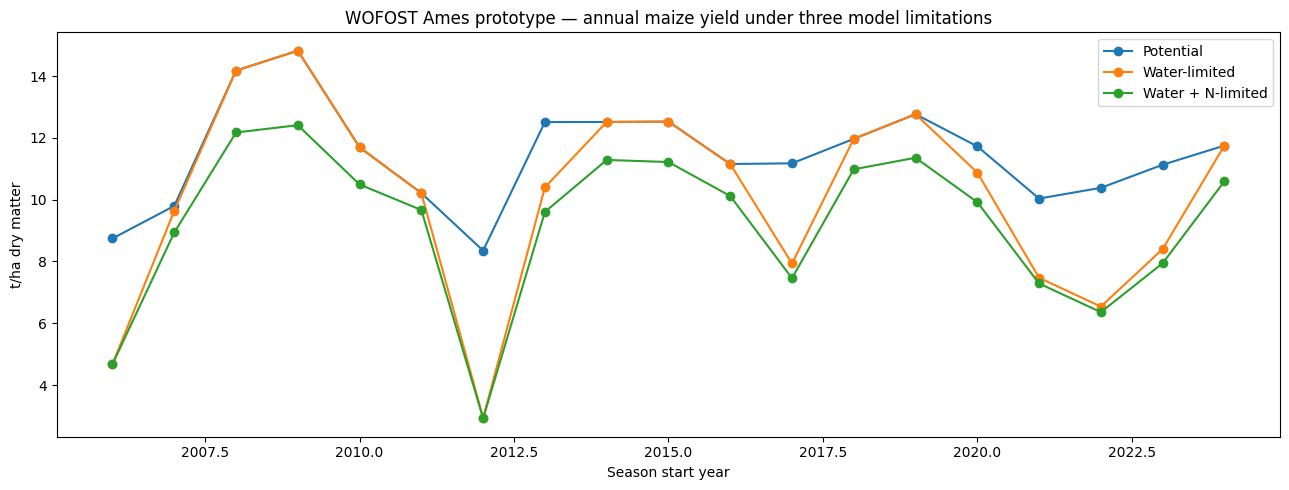

In [17]:
if PCSE_AVAILABLE:
    post_spinup = seasons_ames.loc[seasons_ames['year'] > seasons_ames['year'].min()].copy()
    display(post_spinup[['year', 'sowing', 'maturity', 'harvest', 'frost_ended', 'yield_potential_t_ha', 'yield_water_t_ha', 'yield_water_n_t_ha', 'water_pct_of_potential', 'water_n_pct_of_water', 'water_stress_days', 'n_uptake_kg_ha', 'rain_season_mm', 'longest_dry_spell_days']].round(2))

    metric_table = pd.DataFrame({
        'media': post_spinup[['yield_potential_t_ha', 'yield_water_t_ha', 'yield_water_n_t_ha', 'water_stress_days', 'n_uptake_kg_ha', 'rain_season_mm']].mean(),
        'desviacion': post_spinup[['yield_potential_t_ha', 'yield_water_t_ha', 'yield_water_n_t_ha', 'water_stress_days', 'n_uptake_kg_ha', 'rain_season_mm']].std(),
    })
    display(metric_table.round(2))
    ax = post_spinup.set_index('year')[['yield_potential_t_ha', 'yield_water_t_ha', 'yield_water_n_t_ha']].plot(figsize=(13, 5), marker='o')
    ax.set(title='WOFOST Ames prototype — annual maize yield under three model limitations', ylabel='t/ha dry matter', xlabel='Season start year')
    ax.legend(['Potential', 'Water-limited', 'Water + N-limited'])
    plt.tight_layout()
else:
    print('Métricas no disponibles hasta ejecutar WOFOST.')

## 6. Comparación de humedad radicular simulada con SMAP

Como chequeo de dinámica hídrica, se compara el agua total simulada por WOFOST en 0–100 cm con la media diaria SMAP de humedad radicular. Correlación y error solo cuantifican semejanza temporal entre dos productos/modelos con escalas espaciales distintas; SMAP no es verdad de terreno ni este chequeo calibra rendimiento. WOFOST entrega WWLOW como profundidad de agua en el perfil; dividir entre la profundidad del perfil (cm) produce una fracción volumétrica aproximada.

,exploratory comparison
n daily pairs,3564.000
Pearson r,0.838
MAE (m³/m³),0.064


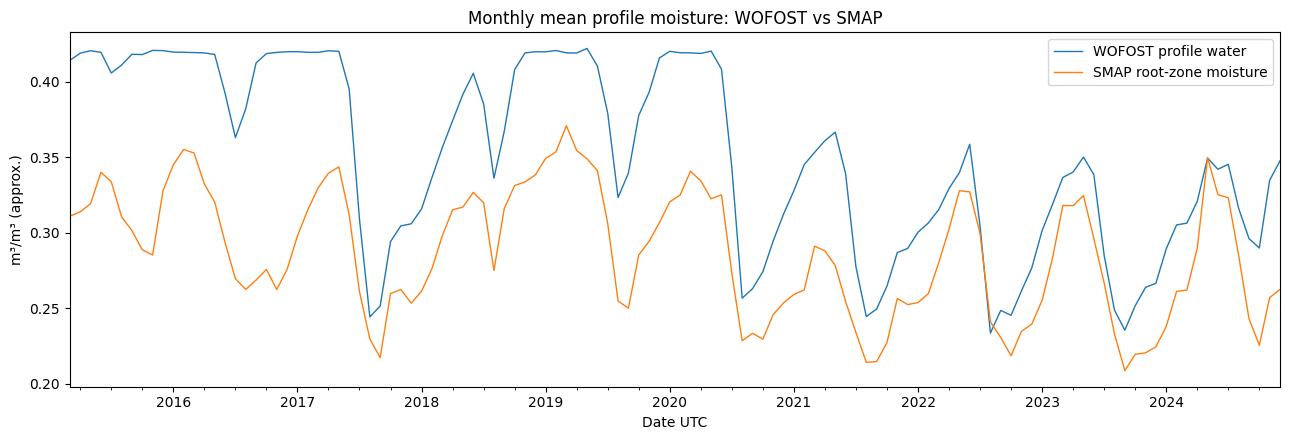

In [18]:
if PCSE_AVAILABLE:
    # WOFOST concatena salidas por temporada; puede repetir la fecha de transición anual.
    # Conservamos el último estado de WOFOST de cada día; SMAP se promedia si repite timestamps.
    wofost_water = daily_ames['WWLOW'].groupby(level=0).last() / soil['RDMSOL']
    wofost_moisture = wofost_water.rename('WOFOST profile water')
    smap_rootzone = smap['sm_rootzone'].groupby(level=0).mean()
    smap_daily = smap_rootzone.resample('D').mean().rename('SMAP root-zone moisture')
    moisture_comparison = pd.concat([wofost_moisture, smap_daily], axis=1).loc['2015-03-31':'2024-12-31'].dropna()
    scores = pd.Series({
        'n daily pairs': len(moisture_comparison),
        'Pearson r': moisture_comparison.corr().iloc[0, 1],
        'MAE (m³/m³)': (moisture_comparison.iloc[:, 0] - moisture_comparison.iloc[:, 1]).abs().mean(),
    })
    display(scores.to_frame('exploratory comparison').round(3))
    moisture_monthly = moisture_comparison.resample('MS').mean()
    ax = moisture_monthly.plot(figsize=(13, 4.5), linewidth=1.0)
    ax.set(title='Monthly mean profile moisture: WOFOST vs SMAP', ylabel='m³/m³ (approx.)', xlabel='Date UTC')
    plt.tight_layout()
else:
    print('Comparación con SMAP omitida: se necesita ejecutar WOFOST.')

## Lectura responsable y siguientes pasos

Este ejercicio permite inspeccionar cómo WOFOST traduce clima diario y parámetros de suelo/cultivo en rendimiento, balance de agua y N. **No es una predicción validada de rendimiento de Ames.** Antes de comparar rotaciones del Corn Belt faltan parámetros locales de cultivares y fechas, manejo/residuos, propiedades hidráulicas de parcela, historial de rotación y rendimientos observados para calibrar/evaluar. La configuración actual incluye supuestos de Texcoco y parámetros de cultivo WOFOST que pueden no representar híbridos de Iowa.

WOFOST tampoco estima por sí solo erosión ni toda la salud del suelo; para esos objetivos se necesitan métricas o modelos complementarios. El próximo notebook usa un objetivo observable y acotado: pronosticar humedad radicular SMAP a 7 días con validación temporal, frente a persistencia y climatología estacional. Ese pronóstico puede informar análisis de riesgo hídrico, pero no reemplaza una predicción de cosecha.